In [4]:
# %%
# Variogram analysis — RF predicted rasters across resolutions vs CHIRPS
#
# Purpose: Quantify whether spatial structure is added at finer RF resolutions
#          by comparing variogram range and nugget:sill ratio across resolutions.
#
# Design decisions fixed:
#   - Random pixel sampling: N = 5000 per raster, fixed seed per month for reproducibility
#   - Lag parameters: lag_dist=10km, lag_tol=5km, n_lag=20 (consistent across ALL resolutions)
#   - Omnidirectional variogram: azm=0, atol=90 (anisotropy not tested here)
#   - Variogram model: exponential only, WLS-fitted (iterative, 3 iterations)
#   - CHIRPS: native 5km source files, test period only (2001-01 to 2005-12)
#   - ERA5L excluded per user decision
#
# Outputs:
#   variogram_monthly_results.csv  — one row per (source × month), all fitted parameters
#   variogram_seasonal_summary.csv — range and nugget:sill aggregated by source × season
#   variogram_range_plot.png       — range vs resolution, seasonal panels
#   variogram_nugget_sill_plot.png — nugget:sill vs resolution, seasonal panels
#
# =============================================================================

# %%
import os
import gc
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import rioxarray as rxr

from pyproj import Proj
from scipy.optimize import curve_fit
from tqdm import tqdm

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ── CONFIGURATION ─────────────────────────────────────────────────────────────

START_YEAR, START_MONTH = 2001, 1
END_YEAR,   END_MONTH   = 2005, 12

RESOLUTIONS = [1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6]

# Root folder containing Resolution_Skill_Test outputs
OUT_ROOT = r"..\Data\Processed\Resolution_Skill_Test"

# The correct path for native CHIRPS monthly sums:
CHIRPS_NATIVE_DIR = r"..\Data\Processed\RegressionModel\Monthly_Rasters\chirps"
# Files: chirps_monthly_sum_YYYYMM.tif  (these are the 1km-resampled versions)
#
# For truly native 5km CHIRPS the user said read from:
CHIRPS_DAILY_NATIVE = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\CHIRPS_prec"
# We will aggregate daily → monthly sums on the fly at native resolution.

# Output directory for variogram results
VARIO_OUT = r"..\Data\Processed\Variogram_Resolution_Analysis"

# Sampling
N_SAMPLE    = 5000     # random pixels per raster
BASE_SEED   = 42       # base random seed; actual seed = BASE_SEED + month_index

# Variogram parameters — consistent across all resolutions
LAG_DIST = 10.0        # km  — bin centre spacing
LAG_TOL  =  5.0        # km  — half-bin tolerance
N_LAG    = 20          # number of lag bins  →  max lag ≈ 200 km
BANDWH   = 9999        # effectively no bandwidth limit (omnidirectional)
AZM      =    0        # azimuth (omnidirectional: atol=90 covers all directions)
ATOL     =   90        # angular tolerance — omnidirectional
TMIN, TMAX = -9999, 9999

MIN_PAIRS_PER_BIN = 30   # bins with fewer pairs are dropped from fitting
MIN_VALID_BINS    =  4   # minimum bins required to attempt fitting

WLS_N_ITER  = 3
WLS_CONV_TOL = 0.01

# UTM zone 45N — appropriate for Nepal
UTM_PROJ = Proj("+proj=utm +zone=45 +ellps=WGS84 +datum=WGS84 +units=m +no_defs")

# Season definitions
SEASONS = {
    'monsoon':      [6, 7, 8, 9],
    'post_monsoon': [10, 11],
    'winter':       [12, 1, 2],
    'pre_monsoon':  [3, 4, 5],
}

os.makedirs(VARIO_OUT, exist_ok=True)

month_range = pd.period_range(
    start=f"{START_YEAR}-{START_MONTH:02d}",
    end=f"{END_YEAR}-{END_MONTH:02d}",
    freq="M"
)

In [5]:
# ── HELPERS ───────────────────────────────────────────────────────────────────

def mlabel(year: int, month: int) -> str:
    return f"{year}{month:02d}"


def res_pred_dir(res_km: float) -> str:
    """Path to predicted rasters for a given resolution."""
    return os.path.join(OUT_ROOT, f"{res_km}km", "Predicted_Rasters")


def season_of(month: int) -> str:
    for s, months in SEASONS.items():
        if month in months:
            return s
    return "unknown"


def raster_to_km_df(raster_path: str) -> pd.DataFrame | None:
    """
    Load a raster, reproject pixel centroids to UTM km, return DataFrame
    with columns [x_km, y_km, value].  Returns None if file missing or empty.
    """
    if not os.path.exists(raster_path):
        return None
    try:
        da = rxr.open_rasterio(raster_path, masked=True)
        if "band" in da.dims:
            da = da.squeeze("band", drop=True)
        df = (
            da.to_dataframe(name="value")
              .reset_index()
              .dropna(subset=["value"])
              .copy()
        )
        da.close()
        if df.empty:
            return None
        # Identify lon/lat columns (may be named x/y or longitude/latitude)
        lon_col = "x" if "x" in df.columns else "longitude"
        lat_col = "y" if "y" in df.columns else "latitude"
        x_m, y_m = UTM_PROJ(df[lon_col].values, df[lat_col].values)
        df["x_km"] = x_m / 1000.0
        df["y_km"] = y_m / 1000.0
        return df[["x_km", "y_km", "value"]].reset_index(drop=True)
    except Exception as e:
        print(f"    WARNING raster_to_km_df [{raster_path}]: {e}")
        return None


def sample_pixels(df: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """Random sample of at most n rows."""
    if len(df) <= n:
        return df.copy()
    return df.sample(n=n, random_state=seed).reset_index(drop=True)


# ── EXPERIMENTAL VARIOGRAM ────────────────────────────────────────────────────

def experimental_variogram(x_km, y_km, values, lag_dist, lag_tol, n_lag, azm, atol, bandwh, tmin, tmax):
    """
    Compute omnidirectional experimental variogram without geostatspy dependency.
    Returns (lag_centres, gamma, n_pairs) arrays of length n_lag.
    """
    # Filter by value range
    mask = (values >= tmin) & (values <= tmax)
    x_km   = x_km[mask]
    y_km   = y_km[mask]
    values = values[mask]
    n      = len(x_km)

    lag_centres = np.arange(1, n_lag + 1) * lag_dist
    gamma       = np.full(n_lag, np.nan)
    n_pairs     = np.zeros(n_lag, dtype=int)

    if n < 10:
        return lag_centres, gamma, n_pairs

    # Vectorised pairwise computation in chunks to avoid memory blowup
    chunk = 500  # process 500 points at a time as the "head" of each pair
    gamma_sum = np.zeros(n_lag)

    for i in range(0, n, chunk):
        end = min(i + chunk, n)
        dx  = x_km[i:end, None] - x_km[None, :]     # (chunk, n)
        dy  = y_km[i:end, None] - y_km[None, :]
        h   = np.sqrt(dx**2 + dy**2)                  # distance in km

        # Direction filter — for omnidirectional (atol=90) this passes everything
        if atol < 90:
            angle = np.degrees(np.arctan2(dy, dx)) % 180
            dir_ok = np.abs(angle - (azm % 180)) <= atol
        else:
            dir_ok = np.ones_like(h, dtype=bool)

        sq_diff = 0.5 * (values[i:end, None] - values[None, :])**2

        for k, centre in enumerate(lag_centres):
            bin_ok = dir_ok & (np.abs(h - centre) <= lag_tol)
            # Only count each pair once: use upper triangle logic within chunk
            # For cross-chunk pairs all are valid; for within-chunk use upper tri
            within = np.zeros_like(bin_ok)
            for ii in range(end - i):
                within[ii, i + ii + 1:] = True  # strictly after current row
            cross = np.ones((end - i, n), dtype=bool)
            cross[:, i:end] = False              # handled by within-chunk logic
            valid = bin_ok & (within | cross)

            n_valid = int(valid.sum())
            if n_valid > 0:
                n_pairs[k]    += n_valid
                gamma_sum[k]  += sq_diff[valid].sum()

        del dx, dy, h, sq_diff, dir_ok
        gc.collect()

    for k in range(n_lag):
        if n_pairs[k] > 0:
            gamma[k] = gamma_sum[k] / n_pairs[k]

    return lag_centres, gamma, n_pairs


# ── EXPONENTIAL MODEL & WLS FITTING ──────────────────────────────────────────

def exponential_model(h, nugget, partial_sill, range_km):
    """
    Exponential variogram.  range_km is the practical range parameter α
    such that γ(h) = nugget + partial_sill * (1 − exp(−h / α)).
    Practical range (correlation → 0.05) ≈ 3α.
    """
    h = np.asarray(h, dtype=float)
    return np.where(
        h == 0,
        nugget,
        nugget + partial_sill * (1.0 - np.exp(-h / range_km))
    )


def iterative_wls_exponential(lag_fit, gamma_fit, npairs_fit, n_bins,
                               bounds, p0,
                               n_iter=3, conv_tol=0.01):
    """
    Iterative WLS fit of the exponential model.
    Returns (nugget, partial_sill, range_km, wls_r2, wls_rmse, converged).
    """
    func = exponential_model

    # Warm-start weights: n_pairs / lag²
    warm_w = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    warm_w = warm_w / warm_w.sum() * n_bins
    sigma  = 1.0 / np.sqrt(np.maximum(warm_w, 1e-12))

    try:
        popt, _ = curve_fit(func, lag_fit, gamma_fit,
                            p0=p0, sigma=sigma, absolute_sigma=True,
                            bounds=bounds, maxfev=10000)
    except RuntimeError:
        return None

    converged = False
    for _ in range(n_iter):
        gamma_model = func(lag_fit, *popt)
        w     = npairs_fit / np.maximum(gamma_model, 1e-6)**2
        w     = w / w.sum() * n_bins
        sigma = 1.0 / np.sqrt(np.maximum(w, 1e-12))
        try:
            popt_new = curve_fit(func, lag_fit, gamma_fit,
                                 p0=popt, sigma=sigma, absolute_sigma=True,
                                 bounds=bounds, maxfev=10000)[0]
        except RuntimeError:
            break
        rel = np.abs((popt_new - popt) / np.maximum(np.abs(popt), 1e-9))
        popt = popt_new
        if rel.max() < conv_tol:
            converged = True
            break

    nugget, partial_sill, range_km = popt
    gamma_model = func(lag_fit, *popt)

    ss_res = np.sum(((gamma_fit - gamma_model) / sigma)**2)
    ss_tot = np.sum(((gamma_fit - gamma_fit.mean()) / sigma)**2)
    wls_r2   = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan
    wls_rmse = float(np.sqrt(np.mean((gamma_fit - gamma_model)**2)))

    return float(nugget), float(partial_sill), float(range_km), wls_r2, wls_rmse, converged


def fit_variogram(df_pixels: pd.DataFrame, seed: int, source_label: str,
                  year: int, month: int) -> dict | None:
    """
    Full pipeline: sample → normalise → variogram → WLS fit.
    Returns a result dict, or None if fitting fails.
    """
    df_s = sample_pixels(df_pixels, N_SAMPLE, seed)

    # N-score transform: rank-based Gaussian transform for stationarity
    n = len(df_s)
    if n < 30:
        return None

    ranks  = df_s["value"].rank(method="first").values
    # Map ranks to standard normal quantiles via inverse CDF
    from scipy.stats import norm as _norm
    ns     = _norm.ppf((ranks - 0.375) / (n + 0.25))
    df_s   = df_s.copy()
    df_s["ns"] = ns

    x_km    = df_s["x_km"].values
    y_km    = df_s["y_km"].values
    ns_vals = df_s["ns"].values

    lag_h, gamma_h, npairs_h = experimental_variogram(
        x_km, y_km, ns_vals,
        LAG_DIST, LAG_TOL, N_LAG,
        AZM, ATOL, BANDWH,
        TMIN, TMAX
    )

    # Domain extent cap: don't use lags > half the domain diagonal
    from scipy.spatial.distance import pdist
    if len(df_s) > 1:
        extent = pdist(df_s[["x_km", "y_km"]].values).max()
        lag_cap = extent / 2.0
    else:
        lag_cap = LAG_DIST * N_LAG

    valid = (
        np.isfinite(gamma_h) &
        (npairs_h >= MIN_PAIRS_PER_BIN) &
        (lag_h <= lag_cap)
    )
    lag_fit    = lag_h[valid]
    gamma_fit  = gamma_h[valid]
    npairs_fit = npairs_h[valid]
    n_bins     = int(valid.sum())

    if n_bins < MIN_VALID_BINS:
        return None

    # Initial parameter guess
    sill_est  = float(np.percentile(gamma_fit, 90))
    range_est = float(lag_fit[np.argmax(gamma_fit >= 0.8 * sill_est)] if np.any(gamma_fit >= 0.8 * sill_est) else lag_fit.mean())
    p0     = [0.05, max(sill_est - 0.05, 0.1), range_est]
    bounds = (
        [0.0,   0.0,   LAG_DIST],            # lower: nugget≥0, cc>0, range≥first bin
        [1.0,   2.0,   np.inf]               # upper: allow sill > 1, no upper bound for range
    )


    result = iterative_wls_exponential(
        lag_fit, gamma_fit, npairs_fit, n_bins,
        bounds, p0,
        n_iter=WLS_N_ITER, conv_tol=WLS_CONV_TOL
    )

    if result is None:
        return None

    nugget, partial_sill, range_km, wls_r2, wls_rmse, converged = result

    total_sill      = nugget + partial_sill
    nugget_sill_ratio = nugget / total_sill if total_sill > 1e-9 else np.nan

    # Practical range = 3 * range_km  (distance at which exp model reaches ~95% of sill)
    practical_range = 3.0 * range_km

    return {
        "source":           source_label,
        "year":             year,
        "month":            month,
        "season":           season_of(month),
        "n_pixels_sampled": n,
        "n_valid_bins":     n_bins,
        "nugget":           round(nugget, 6),
        "partial_sill":     round(partial_sill, 6),
        "total_sill":       round(total_sill, 6),
        "range_param_km":   round(range_km, 3),      # α in exp model
        "practical_range_km": round(practical_range, 3),  # 3α, comparable to spherical range
        "nugget_sill_ratio":  round(nugget_sill_ratio, 6),
        "wls_r2":           round(wls_r2, 6),
        "wls_rmse":         round(wls_rmse, 6),
        "converged":        converged,
    }


# ── CHIRPS NATIVE MONTHLY SUM BUILDER ─────────────────────────────────────────

def chirps_monthly_sum_native(year: int, month: int) -> pd.DataFrame | None:
    """
    Aggregate daily CHIRPS native rasters for year/month to a monthly sum.
    Returns pixel DataFrame [x_km, y_km, value] at native 5km resolution.
    Files expected: CHIRPS_prec_YYYYMMDD.tif
    """
    import calendar
    days_in_month = calendar.monthrange(year, month)[1]
    pattern = os.path.join(CHIRPS_DAILY_NATIVE, f"CHIRPS_prec_{year}{month:02d}*.tif")
    files   = sorted(glob.glob(pattern))
    if not files:
        return None

    arrays = []
    ref_da = None
    for f in files:
        try:
            da = rxr.open_rasterio(f, masked=True)
            if "band" in da.dims:
                da = da.squeeze("band", drop=True)
            if ref_da is None:
                ref_da = da
                arrays.append(da.values.astype(np.float32))
            else:
                # reproject to match first file's grid if needed
                da_r = da.rio.reproject_match(ref_da)
                arrays.append(da_r.values.astype(np.float32))
                da_r.close()
            da.close()
        except Exception:
            continue

    if not arrays or ref_da is None:
        return None

    monthly_sum = np.nansum(np.stack(arrays, axis=0), axis=0)
    monthly_sum[np.all(np.isnan(np.stack(arrays, axis=0)), axis=0)] = np.nan

    # Build coordinate dataframe from reference raster
    x_coords = ref_da.coords["x"].values
    y_coords = ref_da.coords["y"].values
    xx, yy   = np.meshgrid(x_coords, y_coords)
    vals     = monthly_sum.ravel()
    lons     = xx.ravel()
    lats     = yy.ravel()

    mask = np.isfinite(vals) & (vals >= 0)
    df   = pd.DataFrame({"lon": lons[mask], "lat": lats[mask], "value": vals[mask]})
    if df.empty:
        return None

    x_m, y_m  = UTM_PROJ(df["lon"].values, df["lat"].values)
    df["x_km"] = x_m / 1000.0
    df["y_km"] = y_m / 1000.0

    del ref_da, arrays
    gc.collect()
    return df[["x_km", "y_km", "value"]].reset_index(drop=True)

Months: 100%|██████████| 60/60 [2:16:43<00:00, 136.72s/it]  



  Monthly results saved: ..\Data\Processed\Variogram_Resolution_Analysis\variogram_monthly_results.csv
  Rows: 720  |  Sources: ['RF_1km', 'RF_1.5km', 'RF_2km', 'RF_2.5km', 'RF_3km', 'RF_3.5km', 'RF_4km', 'RF_4.5km', 'RF_5km', 'RF_5.5km', 'RF_6km', 'CHIRPS_native']
  Seasonal summary saved: ..\Data\Processed\Variogram_Resolution_Analysis\variogram_seasonal_summary.csv

  Seasonal summary (practical range, km):
  ────────────────────────────────────────────────────────────────────────────────
season          winter  pre_monsoon  monsoon  post_monsoon
source                                                    
CHIRPS_native  1308.25      1210.13  1103.51        410.78
RF_1.5km        961.52      1170.28  1133.43       1102.10
RF_1km          935.25      1152.42  1090.57       1049.92
RF_2.5km        875.61      1062.85  1139.05       1028.57
RF_2km          847.79      1171.98  1130.85        971.89
RF_3.5km        897.58      1037.57  1117.19       1040.55
RF_3km          922.36      10

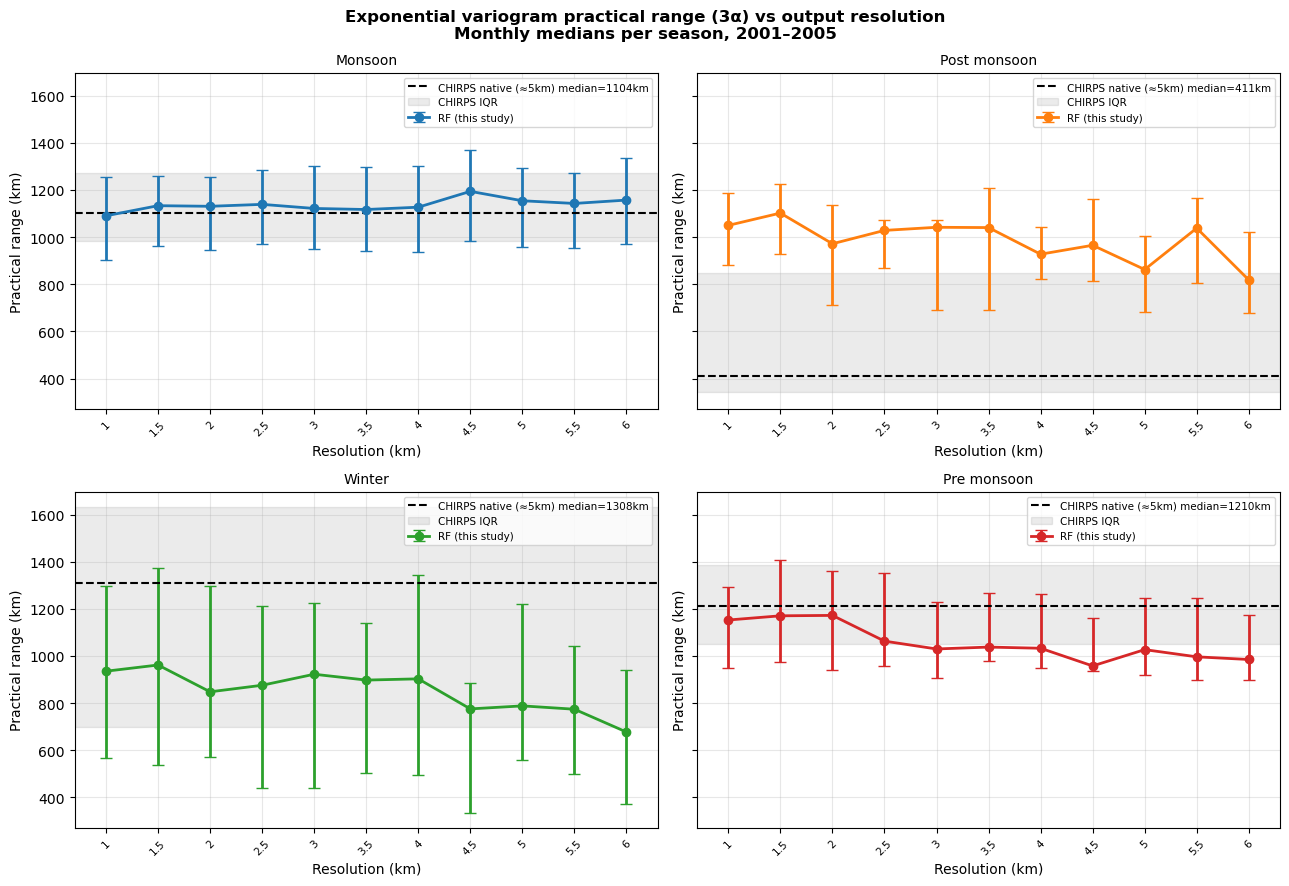

  Range plot saved: ..\Data\Processed\Variogram_Resolution_Analysis\variogram_range_plot.png


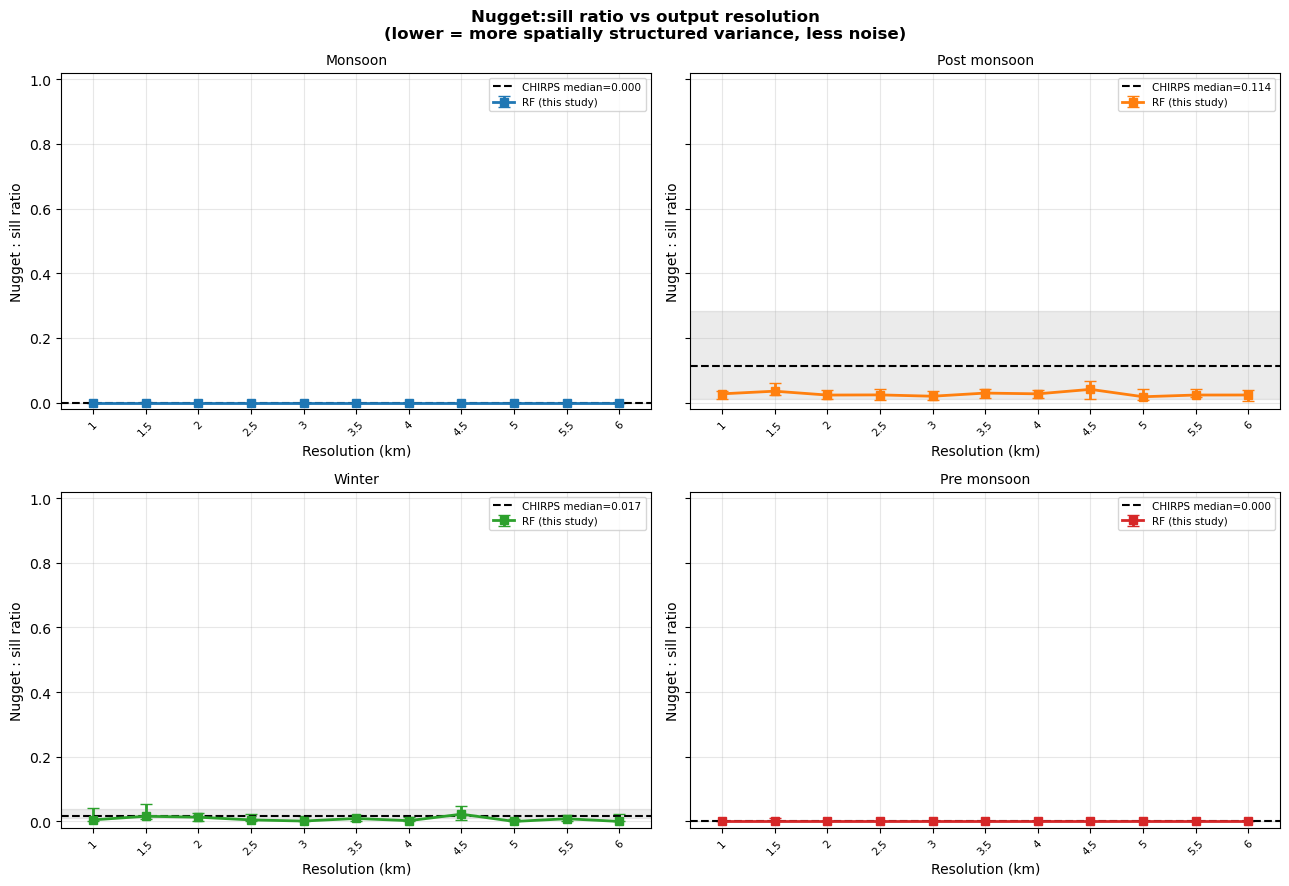

  Nugget:sill plot saved: ..\Data\Processed\Variogram_Resolution_Analysis\variogram_nugget_sill_plot.png


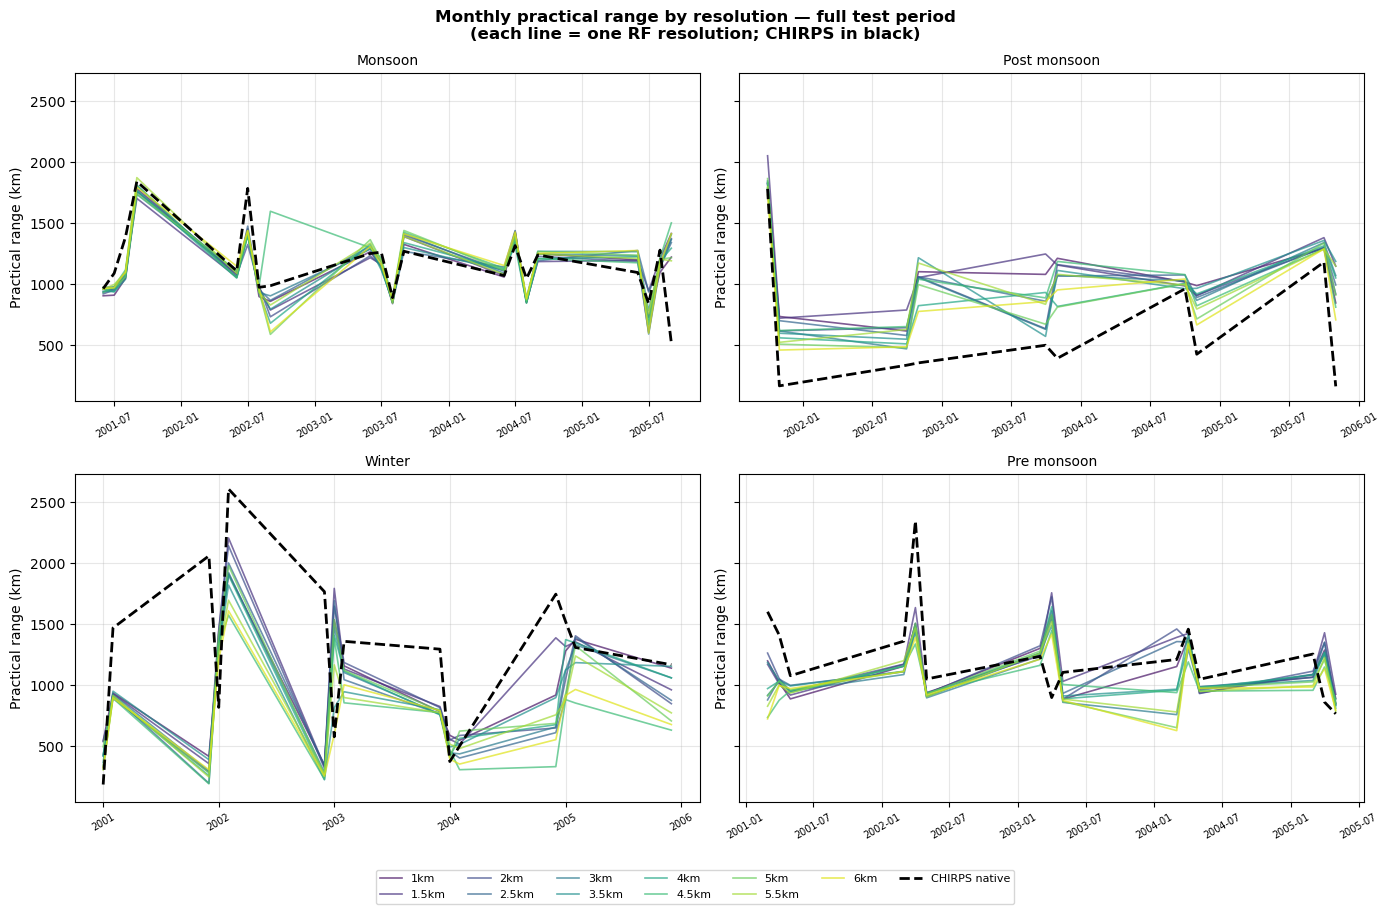

  Time series plot saved: ..\Data\Processed\Variogram_Resolution_Analysis\variogram_range_timeseries.png

Variogram analysis complete.
All outputs → ..\Data\Processed\Variogram_Resolution_Analysis


In [6]:
# ── MAIN LOOP ─────────────────────────────────────────────────────────────────

results = []
month_index = 0  # incremented per period to vary seed

for period in tqdm(month_range, desc="Months"):
    year, month = period.year, period.month
    label       = mlabel(year, month)
    seed        = BASE_SEED + month_index
    month_index += 1

    # ── RF resolutions ────────────────────────────────────────────────────
    for res_km in RESOLUTIONS:
        pred_path = os.path.join(
            res_pred_dir(res_km),
            f"pred_monthly_{label}.tif"
        )
        df_px = raster_to_km_df(pred_path)
        if df_px is None:
            tqdm.write(f"  [{label}] [{res_km}km RF] raster not found — skipping")
            continue

        row = fit_variogram(df_px, seed, source_label=f"RF_{res_km}km", year=year, month=month)
        if row is not None:
            results.append(row)
        else:
            tqdm.write(f"  [{label}] [{res_km}km RF] variogram fit failed")

        del df_px
        gc.collect()

    # ── CHIRPS native ─────────────────────────────────────────────────────
    df_chirps = chirps_monthly_sum_native(year, month)
    if df_chirps is None:
        tqdm.write(f"  [{label}] [CHIRPS native] no daily files found — skipping")
    else:
        row = fit_variogram(df_chirps, seed, source_label="CHIRPS_native", year=year, month=month)
        if row is not None:
            results.append(row)
        else:
            tqdm.write(f"  [{label}] [CHIRPS native] variogram fit failed")
        del df_chirps
        gc.collect()

# ── SAVE MONTHLY RESULTS ──────────────────────────────────────────────────────

df_results = pd.DataFrame(results)

if df_results.empty:
    print("\nNo variogram results produced — check raster paths and try again.")
else:
    monthly_path = os.path.join(VARIO_OUT, "variogram_monthly_results.csv")
    df_results.to_csv(monthly_path, index=False)
    print(f"\n  Monthly results saved: {monthly_path}")
    print(f"  Rows: {len(df_results)}  |  Sources: {df_results['source'].unique().tolist()}")

    # ── SEASONAL SUMMARY ──────────────────────────────────────────────────────
    # For each source × season: median and IQR of practical_range_km and nugget_sill_ratio
    # across all months in that season (pooled across years)

    seasonal_rows = []
    for (source, season), grp in df_results.groupby(["source", "season"]):
        n_months = len(grp)
        pr       = grp["practical_range_km"]
        ns       = grp["nugget_sill_ratio"]
        r2       = grp["wls_r2"]
        seasonal_rows.append({
            "source":                source,
            "season":                season,
            "n_months":              n_months,
            "range_median_km":       round(pr.median(), 2),
            "range_mean_km":         round(pr.mean(), 2),
            "range_q25_km":          round(pr.quantile(0.25), 2),
            "range_q75_km":          round(pr.quantile(0.75), 2),
            "nugget_sill_median":    round(ns.median(), 4),
            "nugget_sill_mean":      round(ns.mean(), 4),
            "nugget_sill_q25":       round(ns.quantile(0.25), 4),
            "nugget_sill_q75":       round(ns.quantile(0.75), 4),
            "wls_r2_median":         round(r2.median(), 4),
        })

    df_seasonal = pd.DataFrame(seasonal_rows)

    # ── Add resolution_km column for sorting/plotting ─────────────────────
    def source_to_res(s):
        if s == "CHIRPS_native":
            return 5.0   # native CHIRPS ~5km
        try:
            return float(s.replace("RF_", "").replace("km", ""))
        except ValueError:
            return np.nan

    df_seasonal["resolution_km"] = df_seasonal["source"].apply(source_to_res)
    df_results["resolution_km"]  = df_results["source"].apply(source_to_res)

    df_seasonal = df_seasonal.sort_values(["season", "resolution_km"]).reset_index(drop=True)

    seasonal_path = os.path.join(VARIO_OUT, "variogram_seasonal_summary.csv")
    df_seasonal.to_csv(seasonal_path, index=False)
    print(f"  Seasonal summary saved: {seasonal_path}")

    # ── PRINT SUMMARY TABLE ───────────────────────────────────────────────
    print("\n  Seasonal summary (practical range, km):")
    print("  " + "─" * 80)
    pivot_range = df_seasonal.pivot(
        index="source", columns="season", values="range_median_km"
    )
    season_order = ["winter", "pre_monsoon", "monsoon", "post_monsoon"]
    pivot_range  = pivot_range[[s for s in season_order if s in pivot_range.columns]]
    print(pivot_range.to_string())

    print("\n  Seasonal summary (nugget:sill ratio):")
    print("  " + "─" * 80)
    pivot_ns = df_seasonal.pivot(
        index="source", columns="season", values="nugget_sill_median"
    )
    pivot_ns = pivot_ns[[s for s in season_order if s in pivot_ns.columns]]
    print(pivot_ns.to_string())

    # ── PLOTS ─────────────────────────────────────────────────────────────

    season_order_plot = ["monsoon", "post_monsoon", "winter", "pre_monsoon"]
    season_colors     = {
        "monsoon":      "#1f77b4",
        "post_monsoon": "#ff7f0e",
        "winter":       "#2ca02c",
        "pre_monsoon":  "#d62728",
    }

    # Resolve RF-resolution sources and add CHIRPS at x=5
    rf_resolutions = sorted(RESOLUTIONS)

    # ── Plot 1: Practical Range vs Resolution ─────────────────────────────
    fig1, axes1 = plt.subplots(2, 2, figsize=(13, 9), sharex=False, sharey=True)
    fig1.suptitle(
        "Exponential variogram practical range (3α) vs output resolution\n"
        "Monthly medians per season, 2001–2005",
        fontsize=12, fontweight='bold'
    )
    axes1 = axes1.ravel()

    for ax, season in zip(axes1, season_order_plot):
        sub = df_seasonal[df_seasonal["season"] == season].copy()
        if sub.empty:
            ax.set_visible(False)
            continue

        # RF points
        rf_sub = sub[sub["source"] != "CHIRPS_native"].sort_values("resolution_km")
        ax.errorbar(
            rf_sub["resolution_km"],
            rf_sub["range_median_km"],
            yerr=[
                rf_sub["range_median_km"] - rf_sub["range_q25_km"],
                rf_sub["range_q75_km"]    - rf_sub["range_median_km"],
            ],
            fmt='o-', color=season_colors.get(season, "navy"),
            linewidth=2, markersize=6, capsize=4, label="RF (this study)"
        )

        # CHIRPS native point
        chirps_sub = sub[sub["source"] == "CHIRPS_native"]
        if not chirps_sub.empty:
            ax.axhline(
                float(chirps_sub["range_median_km"].values[0]),
                color="black", linestyle="--", linewidth=1.5,
                label=f"CHIRPS native (≈5km) median={chirps_sub['range_median_km'].values[0]:.0f}km"
            )
            ax.fill_between(
                [rf_resolutions[0] - 0.3, rf_resolutions[-1] + 0.3],
                float(chirps_sub["range_q25_km"].values[0]),
                float(chirps_sub["range_q75_km"].values[0]),
                color="black", alpha=0.08, label="CHIRPS IQR"
            )

        ax.set_title(season.replace("_", " ").capitalize(), fontsize=10)
        ax.set_xlabel("Resolution (km)")
        ax.set_ylabel("Practical range (km)")
        ax.legend(fontsize=7.5)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(rf_resolutions[0] - 0.3, rf_resolutions[-1] + 0.3)
        ax.set_xticks(rf_resolutions)
        ax.set_xticklabels([str(r) for r in rf_resolutions], rotation=45, fontsize=7.5)

    plt.tight_layout()
    range_plot_path = os.path.join(VARIO_OUT, "variogram_range_plot.png")
    plt.savefig(range_plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  Range plot saved: {range_plot_path}")

    # ── Plot 2: Nugget:Sill Ratio vs Resolution ───────────────────────────
    fig2, axes2 = plt.subplots(2, 2, figsize=(13, 9), sharex=False, sharey=True)
    fig2.suptitle(
        "Nugget:sill ratio vs output resolution\n"
        "(lower = more spatially structured variance, less noise)",
        fontsize=12, fontweight='bold'
    )
    axes2 = axes2.ravel()

    for ax, season in zip(axes2, season_order_plot):
        sub = df_seasonal[df_seasonal["season"] == season].copy()
        if sub.empty:
            ax.set_visible(False)
            continue

        rf_sub = sub[sub["source"] != "CHIRPS_native"].sort_values("resolution_km")
        ax.errorbar(
            rf_sub["resolution_km"],
            rf_sub["nugget_sill_median"],
            yerr=[
                rf_sub["nugget_sill_median"] - rf_sub["nugget_sill_q25"],
                rf_sub["nugget_sill_q75"]    - rf_sub["nugget_sill_median"],
            ],
            fmt='s-', color=season_colors.get(season, "navy"),
            linewidth=2, markersize=6, capsize=4, label="RF (this study)"
        )

        chirps_sub = sub[sub["source"] == "CHIRPS_native"]
        if not chirps_sub.empty:
            ax.axhline(
                float(chirps_sub["nugget_sill_median"].values[0]),
                color="black", linestyle="--", linewidth=1.5,
                label=f"CHIRPS median={chirps_sub['nugget_sill_median'].values[0]:.3f}"
            )
            ax.fill_between(
                [rf_resolutions[0] - 0.3, rf_resolutions[-1] + 0.3],
                float(chirps_sub["nugget_sill_q25"].values[0]),
                float(chirps_sub["nugget_sill_q75"].values[0]),
                color="black", alpha=0.08
            )

        ax.set_title(season.replace("_", " ").capitalize(), fontsize=10)
        ax.set_xlabel("Resolution (km)")
        ax.set_ylabel("Nugget : sill ratio")
        ax.legend(fontsize=7.5)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(rf_resolutions[0] - 0.3, rf_resolutions[-1] + 0.3)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xticks(rf_resolutions)
        ax.set_xticklabels([str(r) for r in rf_resolutions], rotation=45, fontsize=7.5)

    plt.tight_layout()
    ns_plot_path = os.path.join(VARIO_OUT, "variogram_nugget_sill_plot.png")
    plt.savefig(ns_plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  Nugget:sill plot saved: {ns_plot_path}")

    # ── Plot 3: Monthly time series of range per resolution (spaghetti) ───
    fig3, axes3 = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
    fig3.suptitle(
        "Monthly practical range by resolution — full test period\n"
        "(each line = one RF resolution; CHIRPS in black)",
        fontsize=12, fontweight='bold'
    )
    axes3 = axes3.ravel()
    cmap  = plt.cm.viridis(np.linspace(0.05, 0.95, len(rf_resolutions)))

    for ax, season in zip(axes3, season_order_plot):
        sub = df_results[df_results["season"] == season].copy()
        if sub.empty:
            ax.set_visible(False)
            continue

        sub["period"] = pd.to_datetime(
            sub["year"].astype(str) + sub["month"].astype(str).str.zfill(2),
            format="%Y%m"
        )

        for i, res_km in enumerate(rf_resolutions):
            rsub = sub[sub["source"] == f"RF_{res_km}km"].sort_values("period")
            if rsub.empty:
                continue
            ax.plot(rsub["period"], rsub["practical_range_km"],
                    linewidth=1.2, alpha=0.7, color=cmap[i], label=f"{res_km}km")

        csub = sub[sub["source"] == "CHIRPS_native"].sort_values("period")
        if not csub.empty:
            ax.plot(csub["period"], csub["practical_range_km"],
                    linewidth=2, color="black", linestyle="--", label="CHIRPS native")

        ax.set_title(season.replace("_", " ").capitalize(), fontsize=10)
        ax.set_ylabel("Practical range (km)")
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis='x', rotation=30, labelsize=7)

    # Shared legend outside subplots
    handles, labels = axes3[0].get_legend_handles_labels()
    fig3.legend(handles, labels, loc="lower center", ncol=7,
                fontsize=8, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    ts_plot_path = os.path.join(VARIO_OUT, "variogram_range_timeseries.png")
    plt.savefig(ts_plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  Time series plot saved: {ts_plot_path}")

print("\nVariogram analysis complete.")
print(f"All outputs → {VARIO_OUT}")